# NN_L2_var_backtest

**One-day 99 % value at risk of the S&P 500 from a quantile MLP trained with the pinball loss (ensemble of 5 seeds), against 250-day historical simulation, with violations and the Kupiec test, test period from 2020.**

Neural Networks and Deep Learning (NN), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L2/NN_L2_var_backtest/NN_L2_var_backtest.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 2 of *Neural Networks and Deep Learning*: the chart `var_backtest` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

nn: violations = 18   [var.nn.viol]
nn: Kupiec p-value = 0.84   [var.nn.p]
hs: violations = 31   [var.hs.viol]
hs: Kupiec p-value = 0.003   [var.hs.p]


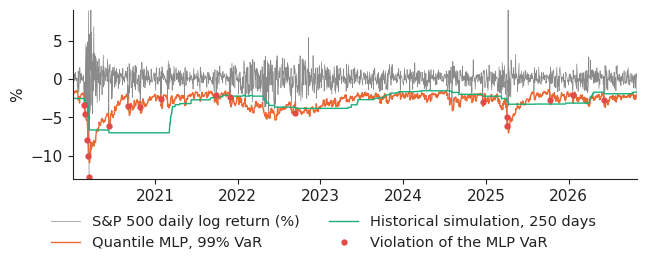

In [3]:
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from scipy import stats
torch.set_num_threads(1)
SEED = 20261108
ca = pd.read_csv(DATA + 'california_housing.csv')
feat = [c for c in ca.columns if c != 'MedHouseVal_100k_usd']
Xc = ca[feat].values.astype(np.float32); yc = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
i_tr, i_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, random_state=SEED)
mu, sd = Xc[i_tr].mean(0), Xc[i_tr].std(0); Z = (Xc - mu) / sd
Xtr, Xva, Xte, ytr, yva, yte = Z[i_tr], Z[i_va], Z[i_te], yc[i_tr], yc[i_va], yc[i_te]
lin = LinearRegression().fit(Xtr, ytr)
mse_lin_val = float(np.mean((lin.predict(Xva) - yva) ** 2)); mse_lin_te = float(np.mean((lin.predict(Xte) - yte) ** 2))

def make_mlp(d, hidden=(64, 64), act=nn.ReLU):
    layers, k = [], d
    for h in hidden:
        layers += [nn.Linear(k, h), act()]; k = h
    return nn.Sequential(*layers, nn.Linear(k, 1))

def make_opt(name, params, lr):
    return {'sgd': lambda: torch.optim.SGD(params, lr=lr), 'momentum': lambda: torch.optim.SGD(params, lr=lr, momentum=0.9),
            'rmsprop': lambda: torch.optim.RMSprop(params, lr=lr, alpha=0.99), 'adam': lambda: torch.optim.Adam(params, lr=lr),
            'adamw': lambda: torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)}[name]()

def run_reg(opt_name, lr, seed=0, epochs=60, bs=128, sched=None):
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = make_mlp(Xtr.shape[1]); opt = make_opt(opt_name, m.parameters(), lr)
    spe = int(np.ceil(len(Xtr) / bs)); total = epochs * spe
    sch = {'step': lambda: torch.optim.lr_scheduler.StepLR(opt, step_size=20 * spe, gamma=0.1),
           'cosine': lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total),
           'onecycle': lambda: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.3)}.get(sched, lambda: None)()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr).view(-1, 1); Xv, yv = torch.tensor(Xva), torch.tensor(yva).view(-1, 1)
    val, lrs = [], []
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); nn.MSELoss()(m(Xt[b]), yt[b]).backward(); opt.step()
            lrs.append(opt.param_groups[0]['lr'])
            if sch is not None:
                sch.step()
        m.eval()
        with torch.no_grad():
            v = float(nn.MSELoss()(m(Xv), yv)); val.append(v if np.isfinite(v) else 1e9)
    with torch.no_grad():
        te = float(nn.MSELoss()(m(torch.tensor(Xte)), torch.tensor(yte).view(-1, 1)))
    return {'val': val, 'test': te if np.isfinite(te) else 1e9, 'lr': lrs[::spe]}
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
px = x[x.ticker == 'SP500'].set_index('date')['adjclose'].dropna()
end = (px.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1); px = px.loc[:end]
r = 100 * np.log(px).diff().dropna()
F = pd.DataFrame({'r': r, 'ar': r.abs(), 's5': r.rolling(5).std(), 's22': r.rolling(22).std(), 's66': r.rolling(66).std(), 'm5': r.rolling(5).mean()})
dfv = pd.concat([F, r.shift(-1).rename('y')], axis=1).dropna(); TAU = 0.01
v_tr = dfv.index <= pd.Timestamp('2016-12-31'); v_va = (dfv.index > pd.Timestamp('2016-12-31')) & (dfv.index <= pd.Timestamp('2019-12-31')); v_te = dfv.index > pd.Timestamp('2019-12-31')
Xv = dfv[F.columns].values.astype(np.float32); Xv = (Xv - Xv[v_tr].mean(0)) / Xv[v_tr].std(0); yv = dfv['y'].values.astype(np.float32)
tdate = pd.Series(r.index, index=r.index).shift(-1).reindex(dfv.index).values
pin = lambda q, y: torch.mean(torch.maximum(TAU * (y - q), (TAU - 1) * (y - q)))
def var_run(seed, epochs=400):
    torch.manual_seed(SEED + seed); m = make_mlp(Xv.shape[1], (32, 32))
    with torch.no_grad():
        m[-1].bias.fill_(float(np.quantile(yv[v_tr], TAU)))
    opt = torch.optim.Adam(m.parameters(), lr=1e-3); rng = np.random.default_rng(SEED + seed)
    Xt, yt = torch.tensor(Xv[v_tr]), torch.tensor(yv[v_tr]).view(-1, 1); Xa, ya = torch.tensor(Xv[v_va]), torch.tensor(yv[v_va]).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), 256):
            b = idx[i:i + 256]; opt.zero_grad(); pin(m(Xt[b]), yt[b]).backward(); opt.step()
        with torch.no_grad():
            vl = float(pin(m(Xa), ya))
        if vl < best - 1e-6:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= 40:
                break
    m.load_state_dict(state)
    with torch.no_grad():
        return m(torch.tensor(Xv)).numpy().ravel()
q = np.mean([var_run(s) for s in range(5)], axis=0)
hs = r.rolling(250).quantile(TAU).reindex(dfv.index).values; yy = dfv['y'].values
for k, qq in (('nn', q), ('hs', hs)):
    viol = yy[v_te] < qq[v_te]; n, xk = len(viol), int(viol.sum()); ph = xk / n
    lr = -2 * ((n - xk) * np.log(1 - TAU) + xk * np.log(TAU) - (n - xk) * np.log(1 - ph) - xk * np.log(ph))
    show(f'var.{k}.viol', f'{k}: violations', xk); show(f'var.{k}.p', f'{k}: Kupiec p-value', round(float(stats.chi2.sf(lr, 1)), 3))
idx = pd.DatetimeIndex(tdate[v_te])
fig, ax = plt.subplots(figsize=(6.6, 2.7))
ax.plot(idx, yy[v_te], color='#8a8a8a', lw=0.5, label='S&P 500 daily log return (%)')
ax.plot(idx, q[v_te], color=PAL['model'], lw=1.0, label='Quantile MLP, 99% VaR')
ax.plot(idx, hs[v_te], color=PAL['benchmark'], lw=1.0, label='Historical simulation, 250 days')
vi = yy[v_te] < q[v_te]; ax.plot(idx[vi], yy[v_te][vi], 'o', color=PAL['positive'], ms=3.5, label='Violation of the MLP VaR')
ax.set_ylim(-13, 9); ax.set_xlim(idx.min(), idx.max()); ax.set_ylabel('%')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.16, 1, 1))
fig.savefig('var_backtest.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()